# Wearable Activity Detective — training & evaluation notebook (real data)

**Question:** Can a small neural network tell *walking* from *walking upstairs* and *walking downstairs*
using only a phone's accelerometer?

**Data:** UCI "Human Activity Recognition Using Smartphones" dataset (Anguita, Ghio, Oneto, Parra & Reyes-Ortiz, 2013),
https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones — licensed CC BY 4.0.
30 volunteers (ages 19–48) wore a Samsung Galaxy S II on the waist. The recordings are already cut into
2.56-second windows (128 readings at 50 Hz, with 50% overlap between neighboring windows). We keep only the three
moving activities and use the raw **body acceleration** signals (gravity already filtered out by the dataset authors).

**Plan**
1. Load the raw windows for walking / upstairs / downstairs.
2. Turn every window into 16 simple numbers (features).
3. Use the dataset's own split **by person**: 21 volunteers for training, 9 different volunteers for testing.
4. Tune and train a small neural network (scikit-learn `MLPClassifier`) using only the training volunteers.
5. Compare it to a simple baseline (always guess the most common training activity) on the test volunteers.
6. Pick one mistake and explain it.
7. Export held-out predictions to `exhibit.json` for the website.

In [1]:
import io, json, os, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
FS = 50            # samples per second
WIN = 128          # samples per window (2.56 s)
ACTIVITIES = ["walking", "upstairs", "downstairs"]
CODES = {1: "walking", 2: "upstairs", 3: "downstairs"}   # dataset's activity_labels.txt
LABELS = {"walking": "Walking", "upstairs": "Climbing stairs (up)", "downstairs": "Going down stairs"}

## 1. Load the data
Put the folder `UCI HAR Dataset` next to this notebook (or in the repo root). In Google Colab, the cell below
downloads it automatically from UCI if it isn't found.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
CANDIDATES = ["UCI HAR Dataset", "../UCI HAR Dataset", os.environ.get("HAR_DIR", "")]
DATA_DIR = next((c for c in CANDIDATES if c and os.path.isdir(c)), None)
if DATA_DIR is None:
    print("Downloading the dataset from UCI (about 60 MB)...")
    outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
    zipfile.ZipFile(io.BytesIO(outer.read("UCI HAR Dataset.zip"))).extractall(".")
    DATA_DIR = "UCI HAR Dataset"
print("Using data in:", DATA_DIR)

def load_split(split):
    y = np.loadtxt(f"{DATA_DIR}/{split}/y_{split}.txt", dtype=int)
    person = np.loadtxt(f"{DATA_DIR}/{split}/subject_{split}.txt", dtype=int)
    sig = lambda ax: np.loadtxt(f"{DATA_DIR}/{split}/Inertial Signals/body_acc_{ax}_{split}.txt")
    # The phone sat upright at the waist, so its x-axis points up-down (it carries gravity in total_acc_x).
    # We relabel axes for the exhibit: up-down = phone x, side-to-side = phone y, forward-back = phone z.
    xyz = np.stack([sig("z"), sig("y"), sig("x")], axis=1)   # order: forward, side, up-down
    keep = np.isin(y, list(CODES))
    return xyz[keep], np.array([CODES[c] for c in y[keep]]), person[keep]

traces_tr, y_train, g_train = load_split("train")
traces_te, y_test, g_test = load_split("test")
print("Train windows:", len(y_train), "from", len(set(g_train)), "people")
print("Test windows: ", len(y_test), "from", len(set(g_test)), "people")
print(pd.crosstab(np.r_[["train"] * len(y_train), ["test"] * len(y_test)], np.r_[y_train, y_test]))

Using data in: UCI HAR Dataset
Train windows: 3285 from 21 people
Test windows:  1387 from 9 people
col_0  downstairs  upstairs  walking
row_0                               
test          420       471      496
train         986      1073     1226


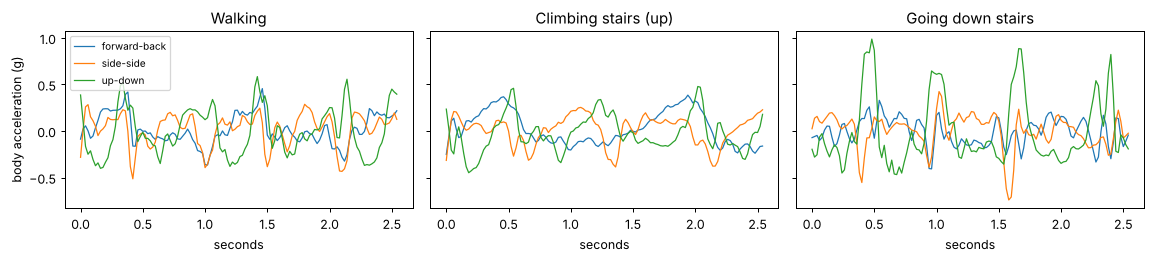

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
t = np.arange(WIN) / FS
for ax, act in zip(axes, ACTIVITIES):
    i = np.where(y_train == act)[0][5]
    for k, name in enumerate(["forward-back", "side-side", "up-down"]):
        ax.plot(t, traces_tr[i, k], label=name, lw=1)
    ax.set_title(LABELS[act]); ax.set_xlabel("seconds")
axes[0].set_ylabel("body acceleration (g)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Turn each window into features
Instead of feeding 384 raw numbers to the network, we summarize each window with 16 easy-to-explain numbers:
how much each direction moves (standard deviation and range), the overall shake (magnitude) and its peaks,
how "spiky" and lopsided the up-down signal is (kurtosis, skew), the **step rhythm** found with a Fourier
transform (dominant frequency), how energy is spread across low / middle / high frequencies, and how often the
up-down signal crosses its average.

In [4]:
def features(xyz):
    fwd, side, up = xyz
    mag = np.sqrt(fwd**2 + side**2 + up**2)
    f = {}
    for name, sig in (("fwd", fwd), ("side", side), ("up", up)):
        f[f"{name}_std"] = sig.std()
        f[f"{name}_range"] = sig.max() - sig.min()
    f["mag_mean"], f["mag_std"], f["mag_max"] = mag.mean(), mag.std(), mag.max()
    f["up_kurtosis"], f["up_skew"] = kurtosis(up), skew(up)
    # zero-padding to 1024 points gives a finer reading of the step rhythm (otherwise it can only be a multiple of 0.39)
    spec = np.abs(np.fft.rfft(up - up.mean(), n=1024)) ** 2
    freqs = np.fft.rfftfreq(1024, 1 / FS)
    band = (freqs > 0.5) & (freqs < 3.5)
    f["step_freq"] = freqs[band][np.argmax(spec[band])]
    total = spec.sum() + 1e-12
    f["energy_low"] = spec[(freqs >= 0.5) & (freqs < 2.5)].sum() / total
    f["energy_mid"] = spec[(freqs >= 2.5) & (freqs < 5)].sum() / total
    f["energy_high"] = spec[freqs >= 5].sum() / total
    f["up_zero_cross"] = np.sum(np.diff(np.sign(up - up.mean())) != 0)
    return f

feat_tr = pd.DataFrame([features(w) for w in traces_tr])
feat_te = pd.DataFrame([features(w) for w in traces_te])
FEATURE_NAMES = list(feat_tr.columns)
X_train, X_test = feat_tr.values, feat_te.values
print(len(FEATURE_NAMES), "features:", FEATURE_NAMES)
feat_tr.groupby(y_train)[["step_freq", "up_std", "mag_max", "up_kurtosis"]].median().round(3)

16 features: ['fwd_std', 'fwd_range', 'side_std', 'side_range', 'up_std', 'up_range', 'mag_mean', 'mag_std', 'mag_max', 'up_kurtosis', 'up_skew', 'step_freq', 'energy_low', 'energy_mid', 'energy_high', 'up_zero_cross']


,step_freq,up_std,mag_max,up_kurtosis
downstairs,1.758,0.371,1.067,-0.402
upstairs,1.611,0.249,0.746,-0.453
walking,1.758,0.220,0.688,-0.571


## 3. Tune the network using only the training volunteers
4-fold cross-validation **grouped by person**, so a volunteer is never in both the training and validation part.
The 9 test volunteers are not touched here.

In [5]:
def make_model(hidden, alpha):
    return make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=2000, random_state=SEED))

results = []
for hidden in [(8,), (16,), (32,), (32, 16)]:
    for alpha in [1e-4, 1e-2, 1e-1, 1.0]:
        scores = []
        for tr, va in GroupKFold(n_splits=4).split(X_train, y_train, g_train):
            m = make_model(hidden, alpha).fit(X_train[tr], y_train[tr])
            scores.append(accuracy_score(y_train[va], m.predict(X_train[va])))
        results.append({"hidden_layers": str(hidden), "alpha": alpha, "cv_accuracy": np.mean(scores)})
tuning = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)
print(tuning.head(8).to_string(index=False))
best = tuning.iloc[0]
BEST_HIDDEN, BEST_ALPHA = eval(best["hidden_layers"]), float(best["alpha"])
print("Chosen:", BEST_HIDDEN, BEST_ALPHA)

hidden_layers  alpha  cv_accuracy
     (32, 16) 1.0000     0.830973
        (32,) 1.0000     0.830062
     (32, 16) 0.1000     0.826612
         (8,) 1.0000     0.826352
     (32, 16) 0.0001     0.824945
     (32, 16) 0.0100     0.820584
        (16,) 1.0000     0.819355
        (32,) 0.0001     0.815437
Chosen: (32, 16) 1.0


## 4. Train the final model and compare it to a baseline on the test volunteers

In [6]:
model = make_model(BEST_HIDDEN, BEST_ALPHA).fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred, proba, classes = model.predict(X_test), model.predict_proba(X_test), list(model.classes_)
base_pred = baseline.predict(X_test)
nn_acc, base_acc = accuracy_score(y_test, pred), accuracy_score(y_test, base_pred)
print(f"Neural network test accuracy: {nn_acc:.1%}")
print(f"Baseline (always '{base_pred[0]}') test accuracy: {base_acc:.1%}")
print(classification_report(y_test, pred, digits=3))
cm = confusion_matrix(y_test, pred, labels=ACTIVITIES)
pd.DataFrame(cm, index=[f"true {a}" for a in ACTIVITIES], columns=[f"pred {a}" for a in ACTIVITIES])

Neural network test accuracy: 85.9%
Baseline (always 'walking') test accuracy: 35.8%
              precision    recall  f1-score   support

  downstairs      0.967     0.826     0.891       420
    upstairs      0.862     0.756     0.805       471
     walking      0.793     0.984     0.878       496

    accuracy                          0.859      1387
   macro avg      0.874     0.855     0.858      1387
weighted avg      0.869     0.859     0.857      1387



,pred walking,pred upstairs,pred downstairs
true walking,488,6,2
true upstairs,105,356,10
true downstairs,22,51,347


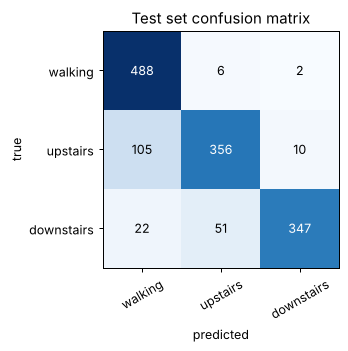

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), ACTIVITIES, rotation=30); ax.set_yticks(range(3), ACTIVITIES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Test set confusion matrix"); plt.tight_layout(); plt.show()

In [8]:
per_person = pd.DataFrame({"person": g_test, "correct": pred == y_test}).groupby("person")["correct"].mean()
print("Accuracy for each test volunteer:\n", (per_person * 100).round(1).to_string())

Accuracy for each test volunteer:
 person
2     90.9
4     98.1
9     67.1
10    83.3
12    88.5
13    87.4
18    81.7
20    73.5
24    98.8


### Which clues does the network rely on most?
**Permutation importance:** shuffle one clue across the test windows (breaking its link to the activity) and see how
much accuracy drops. A big drop means the network leans on that clue. The website's "Build your own walker" sliders
use the top 5.

In [9]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURE_NAMES).sort_values(ascending=False)
TOP_FEATURES = list(importance.index[:5])
print((importance * 100).round(1).rename("accuracy drop (points)").to_string())

mag_std          18.2
energy_high      10.9
step_freq         7.4
up_range          7.2
up_skew           6.5
up_kurtosis       3.9
side_range        2.9
fwd_std           2.9
side_std          2.4
energy_mid        1.8
mag_max           1.6
mag_mean          1.4
up_std            1.1
up_zero_cross     1.0
fwd_range         0.9
energy_low        0.8


## 5. Look closely at one mistake
We look at the most common kind of mistake and pick the example the network was **most confident** about.

In [10]:
conf = proba.max(axis=1)
off = [(cm[i, j], ACTIVITIES[i], ACTIVITIES[j]) for i in range(3) for j in range(3) if i != j]
_, TRUE_A, PRED_A = max(off)
cand = np.where((y_test == TRUE_A) & (pred == PRED_A))[0]
spot = cand[np.argmax(conf[cand])]
typical = feat_tr.groupby(y_train).median()
row = feat_te.iloc[spot]
print(f"Most common mistake: true {TRUE_A} -> predicted {PRED_A} ({max(off)[0]} windows)")
print(f"Spotlight: test window {spot}, volunteer {g_test[spot]}, {conf[spot]:.0%} confident")
cols = ["step_freq", "up_std", "mag_max", "up_kurtosis", "energy_mid"]
print(pd.concat([row[cols].rename("this window"), typical.loc[TRUE_A, cols].rename(f"typical {TRUE_A}"),
                 typical.loc[PRED_A, cols].rename(f"typical {PRED_A}")], axis=1).round(3))

Most common mistake: true upstairs -> predicted walking (105 windows)
Spotlight: test window 377, volunteer 9, 100% confident
             this window  typical upstairs  typical walking
step_freq          1.855             1.611            1.758
up_std             0.150             0.249            0.220
mag_max            0.446             0.746            0.688
up_kurtosis       -0.711            -0.453           -0.571
energy_mid         0.300             0.151            0.203


In [11]:
def closer(feat):
    v, a, b = row[feat], typical.loc[TRUE_A, feat], typical.loc[PRED_A, feat]
    return abs(v - b) < abs(v - a)

clues = []
if closer("step_freq"):
    clues.append(f"a step rhythm of {row.step_freq:.2f} steps per second (typical {LABELS[PRED_A].lower()}: "
                 f"{typical.loc[PRED_A, 'step_freq']:.2f}; typical {LABELS[TRUE_A].lower()}: {typical.loc[TRUE_A, 'step_freq']:.2f})")
if closer("up_std"):
    clues.append(f"an up-down bounce of {row.up_std:.3f} g (typical {LABELS[PRED_A].lower()}: "
                 f"{typical.loc[PRED_A, 'up_std']:.3f} g; typical {LABELS[TRUE_A].lower()}: {typical.loc[TRUE_A, 'up_std']:.3f} g)")
if closer("mag_max"):
    clues.append(f"a strongest jolt of {row.mag_max:.2f} g (typical {LABELS[PRED_A].lower()}: "
                 f"{typical.loc[PRED_A, 'mag_max']:.2f} g; typical {LABELS[TRUE_A].lower()}: {typical.loc[TRUE_A, 'mag_max']:.2f} g)")
clue_text = ("This window had " + "; and ".join(clues) + ". Those numbers look more like the predicted activity "
             "than the real one in the training data.") if clues else (
             "None of the simple summary numbers stands out on its own; the mix of features happened to sit "
             "on the predicted activity's side of the network's boundary.")
SPOTLIGHT_EXPLANATION = (
    f"Volunteer {g_test[spot]} was truly {LABELS[TRUE_A].lower()}, but the network said "
    f"'{LABELS[PRED_A].lower()}' with {conf[spot]:.0%} confidence. {clue_text} "
    "An accelerometer can't feel height change directly, so walking and stairs can look alike. Things that might "
    "have helped: a barometer (air-pressure) reading that shows going up or down, longer windows so the model sees "
    "more steps, the gyroscope signals the dataset also includes, or more training volunteers with different walking styles."
)
print(SPOTLIGHT_EXPLANATION)

Volunteer 9 was truly climbing stairs (up), but the network said 'walking' with 100% confidence. This window had a step rhythm of 1.86 steps per second (typical walking: 1.76; typical climbing stairs (up): 1.61); and an up-down bounce of 0.150 g (typical walking: 0.220 g; typical climbing stairs (up): 0.249 g); and a strongest jolt of 0.45 g (typical walking: 0.69 g; typical climbing stairs (up): 0.75 g). Those numbers look more like the predicted activity than the real one in the training data. An accelerometer can't feel height change directly, so walking and stairs can look alike. Things that might have helped: a barometer (air-pressure) reading that shows going up or down, longer windows so the model sees more steps, the gyroscope signals the dataset also includes, or more training volunteers with different walking styles.


## 6. Export held-out predictions for the website
The site shows a gallery of test-set windows (volunteers the model never saw): a mix of correct predictions and
mistakes, plus the summary numbers the site guide and chatbot rely on.

In [12]:
rng_g = np.random.default_rng(7)
gallery = []
for act in ACTIVITIES:
    right = np.where((y_test == act) & (pred == act))[0]
    wrong = np.where((y_test == act) & (pred != act) & (np.arange(len(y_test)) != spot))[0]
    gallery += list(rng_g.choice(right, 4, replace=False)) + list(rng_g.choice(wrong, min(1, len(wrong)), replace=False))
rest = [int(i) for i in gallery]
rng_g.shuffle(rest)
gallery_ids = [int(spot)] + rest   # the spotlight mistake is listed first; the site shuffles the game order

def pack(i):
    return {
        "id": int(i), "person": int(g_test[i]), "true": y_test[i], "pred": pred[i],
        "probs": {c: round(float(p), 3) for c, p in zip(classes, proba[i])},
        "steps_per_sec": round(float(feat_te.step_freq.iloc[i]), 2),
        "feats": [round(float(v), 6) for v in feat_te.iloc[i].values],   # the 16 inputs the network sees
        "x": np.round(traces_te[i, 0], 3).tolist(),   # forward-back
        "y": np.round(traces_te[i, 1], 3).tolist(),   # side-side
        "z": np.round(traces_te[i, 2], 3).tolist(),   # up-down
    }

typical_steps = {a: round(float(typical.loc[a, "step_freq"]), 2) for a in ACTIVITIES}
exhibit = {
    "activities": ACTIVITIES, "labels": LABELS, "sample_rate_hz": FS, "window_seconds": WIN / FS,
    "data_source": "UCI Human Activity Recognition Using Smartphones (Anguita et al., 2013), CC BY 4.0",
    "summary": {
        "n_train_people": int(len(set(g_train))), "n_test_people": int(len(set(g_test))),
        "n_train_windows": int(len(y_train)), "n_test_windows": int(len(y_test)),
        "nn_accuracy": round(float(nn_acc), 3), "baseline_accuracy": round(float(base_acc), 3),
        "baseline_rule": f"always guess '{base_pred[0]}'",
        "per_class_recall": {a: round(float(cm[k, k] / cm[k].sum()), 3) for k, a in enumerate(ACTIVITIES)},
        "confusion_matrix": cm.tolist(), "hidden_layers": list(BEST_HIDDEN), "alpha": BEST_ALPHA,
        "n_features": len(FEATURE_NAMES), "features": FEATURE_NAMES, "typical_steps_per_sec": typical_steps,
        "test_counts": {a: int((y_test == a).sum()) for a in ACTIVITIES},
        "per_person_accuracy": {int(k): round(float(v), 3) for k, v in per_person.items()},
    },
    "spotlight": {"id": int(spot), "true": TRUE_A, "pred": PRED_A, "explanation": SPOTLIGHT_EXPLANATION},
    "gallery": [pack(i) for i in gallery_ids],
}
# the trained network itself (scaler + weights), so the website can show it working and re-run it in the browser
scaler, mlp = model.named_steps["standardscaler"], model.named_steps["mlpclassifier"]
exhibit["network"] = {
    "features": FEATURE_NAMES, "classes": classes, "activation": mlp.activation, "output": mlp.out_activation_,
    "scaler_mean": np.round(scaler.mean_, 6).tolist(), "scaler_scale": np.round(scaler.scale_, 6).tolist(),
    "weights": [np.round(W, 5).tolist() for W in mlp.coefs_],
    "biases": [np.round(b, 5).tolist() for b in mlp.intercepts_],
    # for the "build your own walker" sliders: each clue's usual range and each activity's typical (median) values
    "top_features": TOP_FEATURES,
    "importance": {f: round(float(v), 4) for f, v in importance.items()},
    "ranges": {f: [round(float(feat_tr[f].quantile(0.02)), 4), round(float(feat_tr[f].quantile(0.98)), 4)] for f in FEATURE_NAMES},
    "typical": {a: [round(float(v), 6) for v in typical.loc[a, FEATURE_NAMES]] for a in ACTIVITIES},
}
OUT_DIR = "../data" if os.path.isdir("../data") else "."
with open(os.path.join(OUT_DIR, "exhibit.json"), "w") as fh:
    json.dump(exhibit, fh)
print("Wrote", os.path.join(OUT_DIR, "exhibit.json"), "with", len(exhibit["gallery"]), "gallery windows")
print(json.dumps({k: v for k, v in exhibit["summary"].items() if k != "features"}, indent=1))

Wrote ../data/exhibit.json with 16 gallery windows
{
 "n_train_people": 21,
 "n_test_people": 9,
 "n_train_windows": 3285,
 "n_test_windows": 1387,
 "nn_accuracy": 0.859,
 "baseline_accuracy": 0.358,
 "baseline_rule": "always guess 'walking'",
 "per_class_recall": {
  "walking": 0.984,
  "upstairs": 0.756,
  "downstairs": 0.826
 },
 "confusion_matrix": [
  [
   488,
   6,
   2
  ],
  [
   105,
   356,
   10
  ],
  [
   22,
   51,
   347
  ]
 ],
 "hidden_layers": [
  32,
  16
 ],
 "alpha": 1.0,
 "n_features": 16,
 "typical_steps_per_sec": {
  "walking": 1.76,
  "upstairs": 1.61,
  "downstairs": 1.76
 },
 "test_counts": {
  "walking": 496,
  "upstairs": 471,
  "downstairs": 420
 },
 "per_person_accuracy": {
  "2": 0.909,
  "4": 0.981,
  "9": 0.671,
  "10": 0.833,
  "12": 0.885,
  "13": 0.874,
  "18": 0.817,
  "20": 0.735,
  "24": 0.988
 }
}
